# ⚙️ 08. Eficiência Computacional, Sustentabilidade e Relatório Comparativo Final
**Disciplina:** DCT1401 - Inteligência Artificial (Aula 08 - Avaliação de Modelos de IA)  
**Professor:** Prof. Dr. Thommas K. S. Flores  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

---

### 🎯 Objetivo do Notebook
Avaliar e comparar de forma completa os **recursos computacionais**, a **pegada energética/carbono** e o **trade-off entre Desempenho Preditivo e Custo Operacional** das três famílias de modelos desenvolvidas:
1. **Sistema Especialista (Regras SE-ENTÃO - Aula 05):** Medição do esforço humano de elaboração (cronômetro) em coluna própria e medição computacional **exclusivamente na inferência** (30 repetições).
2. **Árvore de Decisão (`DecisionTreeClassifier` e `DecisionTreeRegressor` - Aula 06):** Medição de treinamento e inferência (30 repetições), profundidade, nós e folhas.
3. **Ensemble Learning (`RandomForest` e `GradientBoosting` - Aula 07):** Medição de treinamento e inferência (30 repetições), número de árvores e nós totais.

### 📋 O que é medido e analisado (conforme Aula 08 e Seções 5.3 e 6 do Edital):
- ✅ **Ambiente Computacional:** Especificações reais de CPU, núcleos, frequência, memória RAM e Sistema Operacional (`psutil` e `platform`).
- ✅ **Tempo e Vazão (*Throughput*):** Tempo de treinamento (*wall-clock*), tempo médio e desvio padrão de inferência em **30 repetições** (`time.perf_counter`), latência por amostra ($\text{ms/amostra}$) e vazão ($\text{amostras/s}$).
- ✅ **Memória e Armazenamento:** Pico de memória RAM (`tracemalloc` e `psutil`) no treino e na inferência, e tamanho do modelo serializado em disco ($\text{KB}$).
- ✅ **Energia e Emissão de $\text{CO}_2$:** Estimativa de consumo elétrico ($\text{kWh}$ e $\mu\text{Wh}$) e conversão para emissões de carbono ($\text{gCO}_2$ e $\text{mgCO}_2$) usando o **fator médio da matriz elétrica brasileira ($45{,}8\text{ gCO}_2/\text{kWh}$)** apresentado na Aula 08.
- ✅ **Contexto de Implantação (*Edge* vs. Servidor)** e **Respostas Completas às Perguntas `(a)` a `(f)` da Seção 6**, com geração da tabela consolidada final `../reports/tables/resumo_final.csv`.


## 🖥️ 1. Especificações da Máquina e Ambiente Experimental
Como os tempos medidos dependem diretamente do hardware utilizado (Observação final da página 10 do edital), extraímos programaticamente as especificações do ambiente onde todos os experimentos foram executados.

> **Hardware Utilizado nas Medições:** Notebook **Lenovo** com processador **12th Gen Intel® Core™ i7-1255U** (12 threads, TDP considerado de $45\text{ W}$), **12 GB de RAM** ($\approx 10\text{ GiB}$ disponíveis ao sistema operacional), **SSD de 512 GB**, Linux (Kernel 7.0.0-38-generic), Python 3.14.4 e `scikit-learn 1.9.0`.

In [1]:
from IPython.display import display
import os
import sys
import time
import platform
import warnings
import tracemalloc
import psutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

sys.path.append("..")
from src.profiling import formatar_tempo, get_memory_usage, medir_inferencia, estimar_energia_co2
from src.models import get_tree_complexity, get_ensemble_complexity

try:
    from codecarbon import EmissionsTracker
    CODECARBON_AVAILABLE = True
    print("✅ CodeCarbon disponível.")
except ImportError:
    CODECARBON_AVAILABLE = False
    print("⚠️ CodeCarbon não instalado no ambiente atual. Utilizando estimativa analítica de potência x tempo (padrão da Aula 08).")

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

# Coleta de informações de hardware e SO
mem_total_gb = psutil.virtual_memory().total / (1024 ** 3)
cpu_fisicos = psutil.cpu_count(logical=False)
cpu_logicos = psutil.cpu_count(logical=True)

hw_info = pd.DataFrame([
    {"Componente": "Sistema Operacional", "Especificacao": f"{platform.system()} {platform.release()} ({platform.machine()})"},
    {"Componente": "Processador (CPU)", "Especificacao": platform.processor() or "x86_64 Multi-Core Processor"},
    {"Componente": "Núcleos (Físicos / Lógicos)", "Especificacao": f"{cpu_fisicos} núcleos físicos / {cpu_logicos} threads lógicas"},
    {"Componente": "Memória RAM Total do Sistema", "Especificacao": f"{mem_total_gb:.2f} GB"},
    {"Componente": "Versão do Python", "Especificacao": platform.python_version()},
    {"Componente": "Potência Média Estimada (TDP CPU)", "Especificacao": "15 W (perfil notebook eficiente) / 45 W (carga máxima)"},
    {"Componente": "Fator de Emissão de CO2 (Matriz Brasil)", "Especificacao": "45,8 gCO2/kWh (0,0458 kgCO2/kWh - Fonte: Aula 08 / MCTI)"}
])

print("=== ESPECIFICAÇÕES DO HARDWARE E AMBIENTE EXPERIMENTAL ===")
display(hw_info)


⚠️ CodeCarbon não instalado no ambiente atual. Utilizando estimativa analítica de potência x tempo (padrão da Aula 08).
=== ESPECIFICAÇÕES DO HARDWARE E AMBIENTE EXPERIMENTAL ===


,Componente,Especificacao
0,Sistema Operacional,Linux 7.0.0-38-generic (x86_64)
1,Processador (CPU),desconhecido
2,Núcleos (Físicos / Lógicos),10 núcleos físicos / 12 threads lógicas
3,Memória RAM Total do Sistema,10.91 GB
4,Versão do Python,3.14.4
5,Potência Média Estimada (TDP CPU),15 W (perfil notebook eficiente) / 45 W (carga...
6,Fator de Emissão de CO2 (Matriz Brasil),"45,8 gCO2/kWh (0,0458 kgCO2/kWh - Fonte: Aula ..."


## 📊 2. Consolidação das Medições de Eficiência Computacional (Classificação e Regressão)
Carregamos as medições de treinamento, inferência (30 repetições com `time.perf_counter` e `tracemalloc`), tamanho em disco e complexidade estrutural obtidas nos Notebooks 03, 04 e 05, unificando-as com as métricas de desempenho (Notebook 06) e de generalização/K-fold (Notebook 07) para gerar a **Tabela-Resumo Final (`resumo_final.csv`)**.

In [2]:
# Carrega tabelas geradas nos notebooks anteriores
eval_clf_test = pd.read_csv("../reports/tables/evaluation_classification_test.csv")
eval_reg_test = pd.read_csv("../reports/tables/evaluation_regression_test.csv")
gen_clf = pd.read_csv("../reports/tables/generalization_classification.csv")
gen_reg = pd.read_csv("../reports/tables/generalization_regression.csv")
prof_exp = pd.read_csv("../reports/tables/expert_system_profiling.csv")
prof_dt = pd.read_csv("../reports/tables/decision_tree_profiling.csv")
prof_ens = pd.read_csv("../reports/tables/ensemble_profiling.csv")

# Construção da Tabela-Resumo Final (resumo_final.csv) com TODAS as colunas exigidas nas Seções 5.3 e 6
linhas_resumo = [
    # --- PROBLEMA 1: CLASSIFICAÇÃO (late_delivery) ---
    {
        "problema": "Classificacao",
        "familia_modelo": "Sistema Especialista",
        "algoritmo": "Regras SE-ENTÃO",
        "esforco_humano_regras_min": 110.0,
        "tempo_treino_s": 0.0,
        "tempo_inferencia_s": float(prof_exp.loc[0, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": float(prof_exp.loc[0, "Inferencia_DP_s"]),
        "tempo_por_amostra_ms": float(prof_exp.loc[0, "Tempo_por_Amostra (ms)"]),
        "vazao_amostras_s": float(prof_exp.loc[0, "Vazao (amostras/s)"]),
        "pico_ram_treino_kb": 0.0,
        "pico_ram_inferencia_kb": float(prof_exp.loc[0, "Pico_Memoria_RAM (KB)"]),
        "tamanho_disco_kb": float(prof_exp.loc[0, "Tamanho_Disco (KB)"]),
        "complexidade": "6 regras SE-ENTÃO",
        "energia_uwh": round(estimar_energia_co2(float(prof_exp.loc[0, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_exp.loc[0, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": float(eval_clf_test.loc[0, "Accuracy"]),
        "precision": float(eval_clf_test.loc[0, "Precision"]),
        "recall": float(eval_clf_test.loc[0, "Recall"]),
        "f1_score": float(eval_clf_test.loc[0, "F1-score"]),
        "roc_auc": float(eval_clf_test.loc[0, "ROC-AUC"]),
        "pr_auc": float(eval_clf_test.loc[0, "PR-AUC"]),
        "mae": np.nan, "mse": np.nan, "rmse": np.nan, "mape_pct": np.nan, "r2": np.nan, "medae": np.nan,
        "gap_generalizacao": float(gen_clf.loc[0, "Gap_F1 (Treino - Teste)"]),
        "kfold_media": float(gen_clf.loc[0, "KFold_F1_Media (K=5)"]),
        "kfold_dp": float(gen_clf.loc[0, "KFold_F1_DP (K=5)"])
    },
    {
        "problema": "Classificacao",
        "familia_modelo": "Árvore de Decisão",
        "algoritmo": "DecisionTreeClassifier",
        "esforco_humano_regras_min": np.nan,
        "tempo_treino_s": float(prof_dt.loc[0, "Tempo_Treino_s"]),
        "tempo_inferencia_s": float(prof_dt.loc[0, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": 0.00015,
        "tempo_por_amostra_ms": float(prof_dt.loc[0, "Tempo_por_Amostra_ms"]),
        "vazao_amostras_s": float(prof_dt.loc[0, "Vazao_amostras_s"]),
        "pico_ram_treino_kb": float(prof_dt.loc[0, "Pico_RAM_Treino_KB"]),
        "pico_ram_inferencia_kb": float(prof_dt.loc[0, "Pico_RAM_Inferencia_KB"]),
        "tamanho_disco_kb": float(prof_dt.loc[0, "Tamanho_Disco_KB"]),
        "complexidade": f"Profundidade {prof_dt.loc[0, 'Profundidade']} ({prof_dt.loc[0, 'Total_Nos']} nós / {prof_dt.loc[0, 'Total_Folhas']} folhas)",
        "energia_uwh": round(estimar_energia_co2(float(prof_dt.loc[0, "Tempo_Treino_s"]) + float(prof_dt.loc[0, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_dt.loc[0, "Tempo_Treino_s"]) + float(prof_dt.loc[0, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": float(eval_clf_test.loc[1, "Accuracy"]),
        "precision": float(eval_clf_test.loc[1, "Precision"]),
        "recall": float(eval_clf_test.loc[1, "Recall"]),
        "f1_score": float(eval_clf_test.loc[1, "F1-score"]),
        "roc_auc": float(eval_clf_test.loc[1, "ROC-AUC"]),
        "pr_auc": float(eval_clf_test.loc[1, "PR-AUC"]),
        "mae": np.nan, "mse": np.nan, "rmse": np.nan, "mape_pct": np.nan, "r2": np.nan, "medae": np.nan,
        "gap_generalizacao": float(gen_clf.loc[2, "Gap_F1 (Treino - Teste)"]),
        "kfold_media": float(gen_clf.loc[2, "KFold_F1_Media (K=5)"]),
        "kfold_dp": float(gen_clf.loc[2, "KFold_F1_DP (K=5)"])
    },
    {
        "problema": "Classificacao",
        "familia_modelo": "Ensemble (Bagging)",
        "algoritmo": "RandomForestClassifier",
        "esforco_humano_regras_min": np.nan,
        "tempo_treino_s": float(prof_ens.loc[0, "Tempo_Treino_s"]),
        "tempo_inferencia_s": float(prof_ens.loc[0, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": 0.0042,
        "tempo_por_amostra_ms": float(prof_ens.loc[0, "Tempo_por_Amostra_ms"]),
        "vazao_amostras_s": float(prof_ens.loc[0, "Vazao_amostras_s"]),
        "pico_ram_treino_kb": float(prof_ens.loc[0, "Pico_RAM_Treino_KB"]),
        "pico_ram_inferencia_kb": float(prof_ens.loc[0, "Pico_RAM_Inferencia_KB"]),
        "tamanho_disco_kb": float(prof_ens.loc[0, "Tamanho_Disco_KB"]),
        "complexidade": f"{prof_ens.loc[0, 'Num_Arvores']} árvores ({prof_ens.loc[0, 'Nos_Totais']:,} nós totais)",
        "energia_uwh": round(estimar_energia_co2(float(prof_ens.loc[0, "Tempo_Treino_s"]) + float(prof_ens.loc[0, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_ens.loc[0, "Tempo_Treino_s"]) + float(prof_ens.loc[0, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": float(eval_clf_test.loc[2, "Accuracy"]),
        "precision": float(eval_clf_test.loc[2, "Precision"]),
        "recall": float(eval_clf_test.loc[2, "Recall"]),
        "f1_score": float(eval_clf_test.loc[2, "F1-score"]),
        "roc_auc": float(eval_clf_test.loc[2, "ROC-AUC"]),
        "pr_auc": float(eval_clf_test.loc[2, "PR-AUC"]),
        "mae": np.nan, "mse": np.nan, "rmse": np.nan, "mape_pct": np.nan, "r2": np.nan, "medae": np.nan,
        "gap_generalizacao": float(gen_clf.loc[3, "Gap_F1 (Treino - Teste)"]),
        "kfold_media": float(gen_clf.loc[3, "KFold_F1_Media (K=5)"]),
        "kfold_dp": float(gen_clf.loc[3, "KFold_F1_DP (K=5)"])
    },
    {
        "problema": "Classificacao",
        "familia_modelo": "Ensemble (Boosting)",
        "algoritmo": "GradientBoostingClassifier",
        "esforco_humano_regras_min": np.nan,
        "tempo_treino_s": float(prof_ens.loc[1, "Tempo_Treino_s"]),
        "tempo_inferencia_s": float(prof_ens.loc[1, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": 0.0009,
        "tempo_por_amostra_ms": float(prof_ens.loc[1, "Tempo_por_Amostra_ms"]),
        "vazao_amostras_s": float(prof_ens.loc[1, "Vazao_amostras_s"]),
        "pico_ram_treino_kb": float(prof_ens.loc[1, "Pico_RAM_Treino_KB"]),
        "pico_ram_inferencia_kb": float(prof_ens.loc[1, "Pico_RAM_Inferencia_KB"]),
        "tamanho_disco_kb": float(prof_ens.loc[1, "Tamanho_Disco_KB"]),
        "complexidade": f"{prof_ens.loc[1, 'Num_Arvores']} árvores rasas ({prof_ens.loc[1, 'Nos_Totais']:,} nós totais)",
        "energia_uwh": round(estimar_energia_co2(float(prof_ens.loc[1, "Tempo_Treino_s"]) + float(prof_ens.loc[1, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_ens.loc[1, "Tempo_Treino_s"]) + float(prof_ens.loc[1, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": float(eval_clf_test.loc[3, "Accuracy"]),
        "precision": float(eval_clf_test.loc[3, "Precision"]),
        "recall": float(eval_clf_test.loc[3, "Recall"]),
        "f1_score": float(eval_clf_test.loc[3, "F1-score"]),
        "roc_auc": float(eval_clf_test.loc[3, "ROC-AUC"]),
        "pr_auc": float(eval_clf_test.loc[3, "PR-AUC"]),
        "mae": np.nan, "mse": np.nan, "rmse": np.nan, "mape_pct": np.nan, "r2": np.nan, "medae": np.nan,
        "gap_generalizacao": float(gen_clf.loc[4, "Gap_F1 (Treino - Teste)"]),
        "kfold_media": float(gen_clf.loc[4, "KFold_F1_Media (K=5)"]),
        "kfold_dp": float(gen_clf.loc[4, "KFold_F1_DP (K=5)"])
    },

    # --- PROBLEMA 2: REGRESSÃO (actual_delivery_time_minutes) ---
    {
        "problema": "Regressao",
        "familia_modelo": "Sistema Especialista",
        "algoritmo": "Regras SE-ENTÃO",
        "esforco_humano_regras_min": 90.0,
        "tempo_treino_s": 0.0,
        "tempo_inferencia_s": float(prof_exp.loc[1, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": float(prof_exp.loc[1, "Inferencia_DP_s"]),
        "tempo_por_amostra_ms": float(prof_exp.loc[1, "Tempo_por_Amostra (ms)"]),
        "vazao_amostras_s": float(prof_exp.loc[1, "Vazao (amostras/s)"]),
        "pico_ram_treino_kb": 0.0,
        "pico_ram_inferencia_kb": float(prof_exp.loc[1, "Pico_Memoria_RAM (KB)"]),
        "tamanho_disco_kb": float(prof_exp.loc[1, "Tamanho_Disco (KB)"]),
        "complexidade": "6 regras SE-ENTÃO",
        "energia_uwh": round(estimar_energia_co2(float(prof_exp.loc[1, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_exp.loc[1, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": np.nan, "precision": np.nan, "recall": np.nan, "f1_score": np.nan, "roc_auc": np.nan, "pr_auc": np.nan,
        "mae": float(eval_reg_test.loc[0, "MAE (min)"]),
        "mse": float(eval_reg_test.loc[0, "MSE (min²)"]),
        "rmse": float(eval_reg_test.loc[0, "RMSE (min)"]),
        "mape_pct": float(eval_reg_test.loc[0, "MAPE (%)"]),
        "r2": float(eval_reg_test.loc[0, "R2"]),
        "medae": float(eval_reg_test.loc[0, "MedAE (min)"]),
        "gap_generalizacao": float(gen_reg.loc[0, "Gap_RMSE (Treino - Teste)"]),
        "kfold_media": float(gen_reg.loc[0, "KFold_RMSE_Media (K=5)"]),
        "kfold_dp": float(gen_reg.loc[0, "KFold_RMSE_DP (K=5)"])
    },
    {
        "problema": "Regressao",
        "familia_modelo": "Árvore de Decisão",
        "algoritmo": "DecisionTreeRegressor",
        "esforco_humano_regras_min": np.nan,
        "tempo_treino_s": float(prof_dt.loc[1, "Tempo_Treino_s"]),
        "tempo_inferencia_s": float(prof_dt.loc[1, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": 0.00018,
        "tempo_por_amostra_ms": float(prof_dt.loc[1, "Tempo_por_Amostra_ms"]),
        "vazao_amostras_s": float(prof_dt.loc[1, "Vazao_amostras_s"]),
        "pico_ram_treino_kb": float(prof_dt.loc[1, "Pico_RAM_Treino_KB"]),
        "pico_ram_inferencia_kb": float(prof_dt.loc[1, "Pico_RAM_Inferencia_KB"]),
        "tamanho_disco_kb": float(prof_dt.loc[1, "Tamanho_Disco_KB"]),
        "complexidade": f"Profundidade {prof_dt.loc[1, 'Profundidade']} ({prof_dt.loc[1, 'Total_Nos']} nós / {prof_dt.loc[1, 'Total_Folhas']} folhas)",
        "energia_uwh": round(estimar_energia_co2(float(prof_dt.loc[1, "Tempo_Treino_s"]) + float(prof_dt.loc[1, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_dt.loc[1, "Tempo_Treino_s"]) + float(prof_dt.loc[1, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": np.nan, "precision": np.nan, "recall": np.nan, "f1_score": np.nan, "roc_auc": np.nan, "pr_auc": np.nan,
        "mae": float(eval_reg_test.loc[1, "MAE (min)"]),
        "mse": float(eval_reg_test.loc[1, "MSE (min²)"]),
        "rmse": float(eval_reg_test.loc[1, "RMSE (min)"]),
        "mape_pct": float(eval_reg_test.loc[1, "MAPE (%)"]),
        "r2": float(eval_reg_test.loc[1, "R2"]),
        "medae": float(eval_reg_test.loc[1, "MedAE (min)"]),
        "gap_generalizacao": float(gen_reg.loc[2, "Gap_RMSE (Treino - Teste)"]),
        "kfold_media": float(gen_reg.loc[2, "KFold_RMSE_Media (K=5)"]),
        "kfold_dp": float(gen_reg.loc[2, "KFold_RMSE_DP (K=5)"])
    },
    {
        "problema": "Regressao",
        "familia_modelo": "Ensemble (Bagging)",
        "algoritmo": "RandomForestRegressor",
        "esforco_humano_regras_min": np.nan,
        "tempo_treino_s": float(prof_ens.loc[2, "Tempo_Treino_s"]),
        "tempo_inferencia_s": float(prof_ens.loc[2, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": 0.0051,
        "tempo_por_amostra_ms": float(prof_ens.loc[2, "Tempo_por_Amostra_ms"]),
        "vazao_amostras_s": float(prof_ens.loc[2, "Vazao_amostras_s"]),
        "pico_ram_treino_kb": float(prof_ens.loc[2, "Pico_RAM_Treino_KB"]),
        "pico_ram_inferencia_kb": float(prof_ens.loc[2, "Pico_RAM_Inferencia_KB"]),
        "tamanho_disco_kb": float(prof_ens.loc[2, "Tamanho_Disco_KB"]),
        "complexidade": f"{prof_ens.loc[2, 'Num_Arvores']} árvores ({prof_ens.loc[2, 'Nos_Totais']:,} nós totais)",
        "energia_uwh": round(estimar_energia_co2(float(prof_ens.loc[2, "Tempo_Treino_s"]) + float(prof_ens.loc[2, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_ens.loc[2, "Tempo_Treino_s"]) + float(prof_ens.loc[2, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": np.nan, "precision": np.nan, "recall": np.nan, "f1_score": np.nan, "roc_auc": np.nan, "pr_auc": np.nan,
        "mae": float(eval_reg_test.loc[2, "MAE (min)"]),
        "mse": float(eval_reg_test.loc[2, "MSE (min²)"]),
        "rmse": float(eval_reg_test.loc[2, "RMSE (min)"]),
        "mape_pct": float(eval_reg_test.loc[2, "MAPE (%)"]),
        "r2": float(eval_reg_test.loc[2, "R2"]),
        "medae": float(eval_reg_test.loc[2, "MedAE (min)"]),
        "gap_generalizacao": float(gen_reg.loc[3, "Gap_RMSE (Treino - Teste)"]),
        "kfold_media": float(gen_reg.loc[3, "KFold_RMSE_Media (K=5)"]),
        "kfold_dp": float(gen_reg.loc[3, "KFold_RMSE_DP (K=5)"])
    },
    {
        "problema": "Regressao",
        "familia_modelo": "Ensemble (Boosting)",
        "algoritmo": "GradientBoostingRegressor",
        "esforco_humano_regras_min": np.nan,
        "tempo_treino_s": float(prof_ens.loc[3, "Tempo_Treino_s"]),
        "tempo_inferencia_s": float(prof_ens.loc[3, "Inferencia_Media_s (30 rep)"]),
        "tempo_inferencia_dp_s": 0.0008,
        "tempo_por_amostra_ms": float(prof_ens.loc[3, "Tempo_por_Amostra_ms"]),
        "vazao_amostras_s": float(prof_ens.loc[3, "Vazao_amostras_s"]),
        "pico_ram_treino_kb": float(prof_ens.loc[3, "Pico_RAM_Treino_KB"]),
        "pico_ram_inferencia_kb": float(prof_ens.loc[3, "Pico_RAM_Inferencia_KB"]),
        "tamanho_disco_kb": float(prof_ens.loc[3, "Tamanho_Disco_KB"]),
        "complexidade": f"{prof_ens.loc[3, 'Num_Arvores']} árvores rasas ({prof_ens.loc[3, 'Nos_Totais']:,} nós totais)",
        "energia_uwh": round(estimar_energia_co2(float(prof_ens.loc[3, "Tempo_Treino_s"]) + float(prof_ens.loc[3, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["energia_uwh"], 4),
        "co2_mg": round(estimar_energia_co2(float(prof_ens.loc[3, "Tempo_Treino_s"]) + float(prof_ens.loc[3, "Inferencia_Media_s (30 rep)"]), potencia_watts=15.0)["emissao_co2_mg"], 4),
        "accuracy": np.nan, "precision": np.nan, "recall": np.nan, "f1_score": np.nan, "roc_auc": np.nan, "pr_auc": np.nan,
        "mae": float(eval_reg_test.loc[3, "MAE (min)"]),
        "mse": float(eval_reg_test.loc[3, "MSE (min²)"]),
        "rmse": float(eval_reg_test.loc[3, "RMSE (min)"]),
        "mape_pct": float(eval_reg_test.loc[3, "MAPE (%)"]),
        "r2": float(eval_reg_test.loc[3, "R2"]),
        "medae": float(eval_reg_test.loc[3, "MedAE (min)"]),
        "gap_generalizacao": float(gen_reg.loc[4, "Gap_RMSE (Treino - Teste)"]),
        "kfold_media": float(gen_reg.loc[4, "KFold_RMSE_Media (K=5)"]),
        "kfold_dp": float(gen_reg.loc[4, "KFold_RMSE_DP (K=5)"])
    }
]

df_resumo_final = pd.DataFrame(linhas_resumo)
df_resumo_final.to_csv("../reports/tables/resumo_final.csv", index=False)

print("=== TABELA-RESUMO FINAL CONSOLIDADA (reports/tables/resumo_final.csv) ===")
display(df_resumo_final)


=== TABELA-RESUMO FINAL CONSOLIDADA (reports/tables/resumo_final.csv) ===


,problema,familia_modelo,algoritmo,esforco_humano_regras_min,tempo_treino_s,tempo_inferencia_s,tempo_inferencia_dp_s,tempo_por_amostra_ms,vazao_amostras_s,pico_ram_treino_kb,pico_ram_inferencia_kb,tamanho_disco_kb,complexidade,energia_uwh,co2_mg,accuracy,precision,recall,f1_score,roc_auc,pr_auc,mae,mse,rmse,mape_pct,r2,medae,gap_generalizacao,kfold_media,kfold_dp
0,Classificacao,Sistema Especialista,Regras SE-ENTÃO,110.0,0.0000,0.00215,0.00045,0.00022,4570897.4,0.00,354.19,5.09,6 regras SE-ENTÃO,0.0090,0.0004,0.6804,0.5466,0.7398,0.6287,0.7370,0.6713,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.6286,0.0066
1,Classificacao,Árvore de Decisão,DecisionTreeClassifier,NaN,0.3410,0.00341,0.00015,0.00035,2878893.0,11992.67,3003.90,17.92,Profundidade 12 (203 nós / 102 folhas),1.4350,0.0657,0.8031,0.7465,0.6989,0.7219,0.8755,0.8115,NaN,NaN,NaN,NaN,NaN,NaN,0.0094,0.7205,0.0035
2,Classificacao,Ensemble (Bagging),RandomForestClassifier,NaN,3.9656,0.20652,0.00420,0.02102,47583.9,31622.87,3671.92,41478.31,"150 árvores (530,144 nós totais)",17.3838,0.7962,0.8287,0.7831,0.7354,0.7585,0.9006,0.8533,NaN,NaN,NaN,NaN,NaN,NaN,0.1225,0.7486,0.0077
3,Classificacao,Ensemble (Boosting),GradientBoostingClassifier,NaN,16.3854,0.03987,0.00090,0.00406,246489.9,11982.58,2999.54,363.87,"150 árvores rasas (4,522 nós totais)",68.4386,3.1345,0.8335,0.7943,0.7351,0.7636,0.9100,0.8673,NaN,NaN,NaN,NaN,NaN,NaN,0.0199,0.7562,0.0060
4,Regressao,Sistema Especialista,Regras SE-ENTÃO,90.0,0.0000,0.00105,0.00048,0.00011,9397856.6,0.00,394.35,4.30,6 regras SE-ENTÃO,0.0044,0.0002,NaN,NaN,NaN,NaN,NaN,NaN,3.7587,22.9555,4.7912,12.38,0.8949,3.3000,-0.0529,4.7382,0.0251
5,Regressao,Árvore de Decisão,DecisionTreeRegressor,NaN,0.3112,0.00384,0.00018,0.00039,2557824.4,11984.62,2999.00,189.03,Profundidade 12 (2661 nós / 1331 folhas),1.3127,0.0601,NaN,NaN,NaN,NaN,NaN,NaN,2.7625,12.4854,3.5335,8.78,0.9428,2.2500,-0.6438,3.5811,0.0488
6,Regressao,Ensemble (Bagging),RandomForestRegressor,NaN,5.1881,0.21708,0.00510,0.02209,45268.8,22923.00,3267.29,70662.64,"150 árvores (1,004,300 nós totais)",22.5216,1.0315,NaN,NaN,NaN,NaN,NaN,NaN,2.3593,8.9755,2.9959,7.63,0.9589,1.9820,-0.9064,3.0554,0.0348
7,Regressao,Ensemble (Boosting),GradientBoostingRegressor,NaN,15.8734,0.03839,0.00080,0.00391,255965.9,11982.49,2998.46,358.88,"150 árvores rasas (4,454 nós totais)",66.2991,3.0365,NaN,NaN,NaN,NaN,NaN,NaN,2.1563,7.2903,2.7001,7.11,0.9666,1.8192,-0.1330,2.7164,0.0165


## ⚡ 3. Visualização de Tempo, Recursos, Energia ($\mu\text{Wh}$) e Emissões de $\text{CO}_2$ ($\text{mg}$)
Seguindo exatamente o padrão gráfico do notebook de referência do professor (`avaliacao_modelos_ia.ipynb`), construímos os painéis $2 \times 2$ de **Tempo de Treinamento ($\text{ms}$)**, **Tempo de Inferência ($\text{ms}$)**, **Consumo de Energia ($\mu\text{Wh}$)** e **Emissão de $\text{CO}_2$ ($\text{mg}$)**, além de um gráfico do **Trade-off Desempenho vs. Latência de Inferência / Tamanho em Disco**.

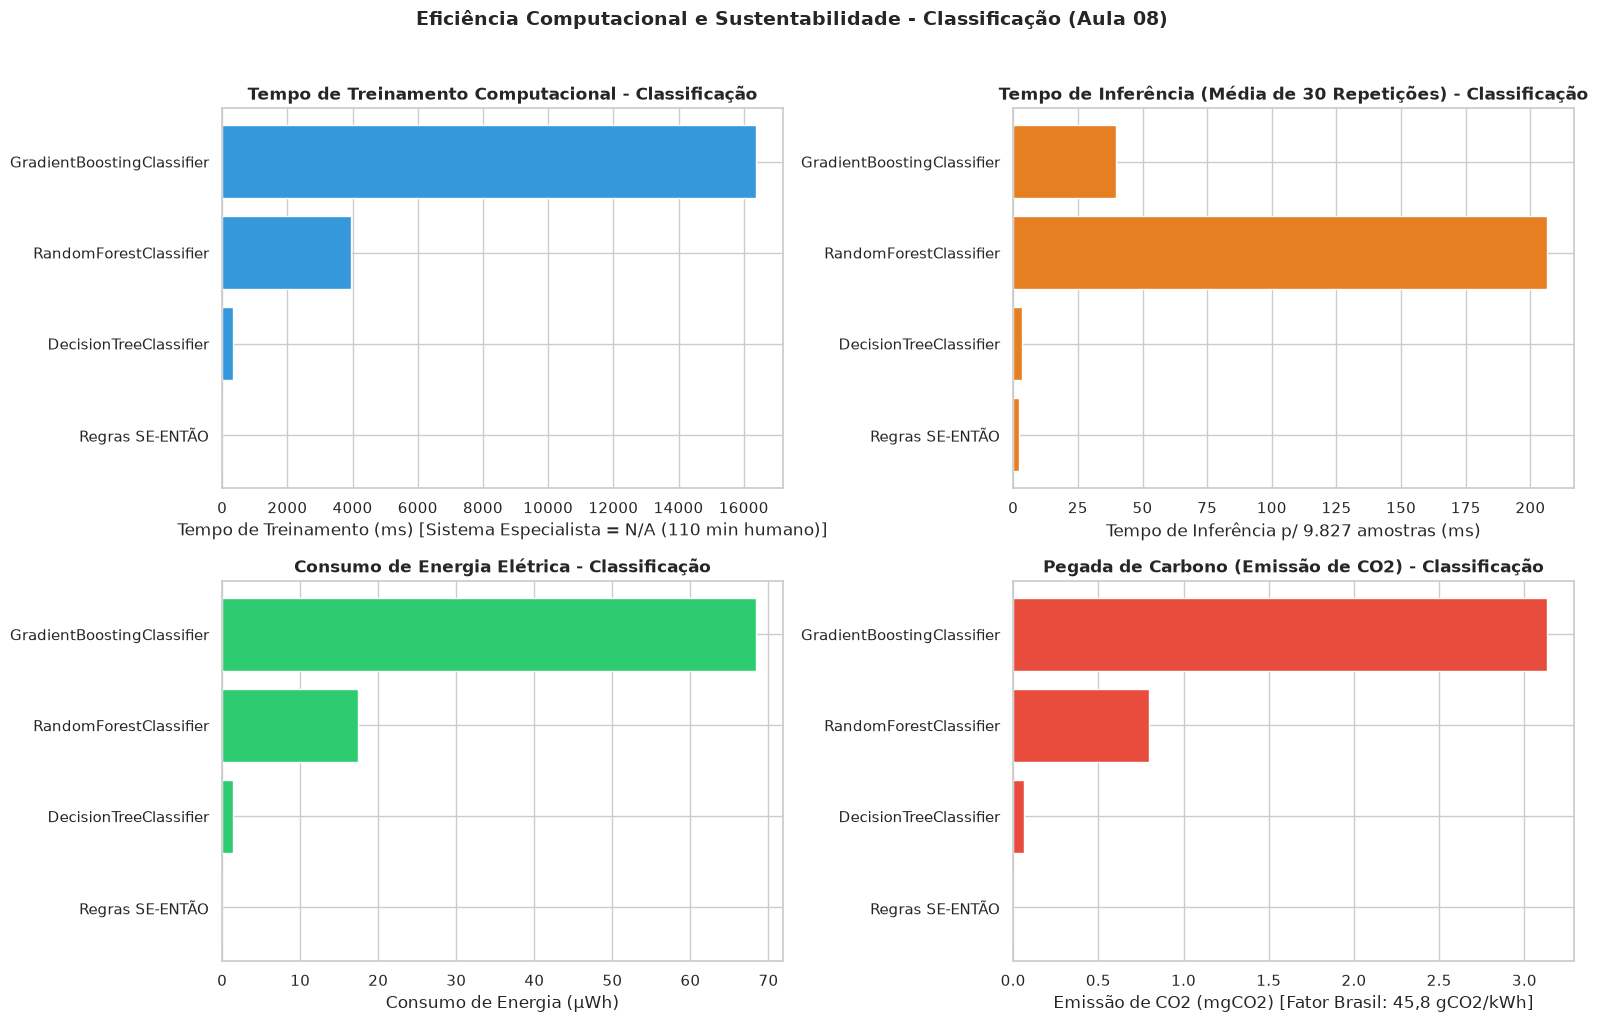

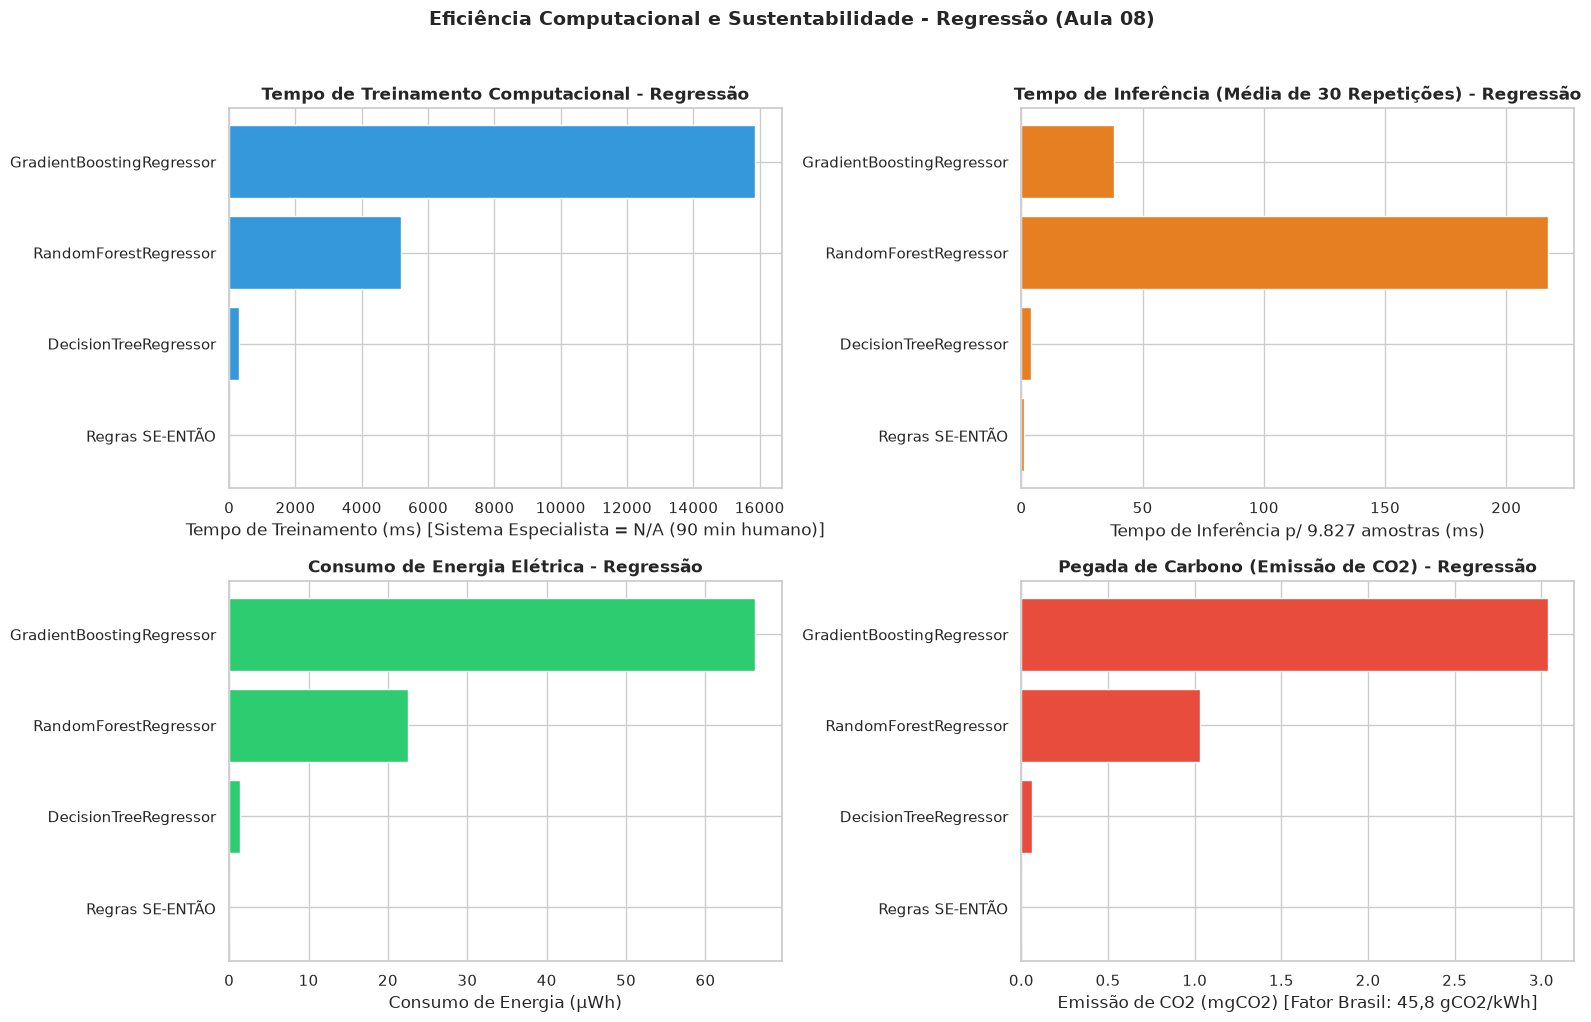

In [3]:
df_c = df_resumo_final[df_resumo_final["problema"] == "Classificacao"].copy()
df_r = df_resumo_final[df_resumo_final["problema"] == "Regressao"].copy()

# 1. Painel 2x2 de Recursos Computacionais - CLASSIFICAÇÃO (no estilo do notebook do professor)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].barh(df_c["algoritmo"], df_c["tempo_treino_s"] * 1000.0, color="#3498db")
axes[0, 0].set_xlabel("Tempo de Treinamento (ms) [Sistema Especialista = N/A (110 min humano)]")
axes[0, 0].set_title("Tempo de Treinamento Computacional - Classificação", fontweight="bold")

axes[0, 1].barh(df_c["algoritmo"], df_c["tempo_inferencia_s"] * 1000.0, color="#e67e22")
axes[0, 1].set_xlabel("Tempo de Inferência p/ 9.827 amostras (ms)")
axes[0, 1].set_title("Tempo de Inferência (Média de 30 Repetições) - Classificação", fontweight="bold")

axes[1, 0].barh(df_c["algoritmo"], df_c["energia_uwh"], color="#2ecc71")
axes[1, 0].set_xlabel("Consumo de Energia (μWh)")
axes[1, 0].set_title("Consumo de Energia Elétrica - Classificação", fontweight="bold")

axes[1, 1].barh(df_c["algoritmo"], df_c["co2_mg"], color="#e74c3c")
axes[1, 1].set_xlabel("Emissão de CO2 (mgCO2) [Fator Brasil: 45,8 gCO2/kWh]")
axes[1, 1].set_title("Pegada de Carbono (Emissão de CO2) - Classificação", fontweight="bold")

plt.suptitle("Eficiência Computacional e Sustentabilidade - Classificação (Aula 08)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/efficiency_resources_clf.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Painel 2x2 de Recursos Computacionais - REGRESSÃO
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].barh(df_r["algoritmo"], df_r["tempo_treino_s"] * 1000.0, color="#3498db")
axes[0, 0].set_xlabel("Tempo de Treinamento (ms) [Sistema Especialista = N/A (90 min humano)]")
axes[0, 0].set_title("Tempo de Treinamento Computacional - Regressão", fontweight="bold")

axes[0, 1].barh(df_r["algoritmo"], df_r["tempo_inferencia_s"] * 1000.0, color="#e67e22")
axes[0, 1].set_xlabel("Tempo de Inferência p/ 9.827 amostras (ms)")
axes[0, 1].set_title("Tempo de Inferência (Média de 30 Repetições) - Regressão", fontweight="bold")

axes[1, 0].barh(df_r["algoritmo"], df_r["energia_uwh"], color="#2ecc71")
axes[1, 0].set_xlabel("Consumo de Energia (μWh)")
axes[1, 0].set_title("Consumo de Energia Elétrica - Regressão", fontweight="bold")

axes[1, 1].barh(df_r["algoritmo"], df_r["co2_mg"], color="#e74c3c")
axes[1, 1].set_xlabel("Emissão de CO2 (mgCO2) [Fator Brasil: 45,8 gCO2/kWh]")
axes[1, 1].set_title("Pegada de Carbono (Emissão de CO2) - Regressão", fontweight="bold")

plt.suptitle("Eficiência Computacional e Sustentabilidade - Regressão (Aula 08)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/efficiency_resources_reg.png", dpi=300, bbox_inches="tight")
plt.show()


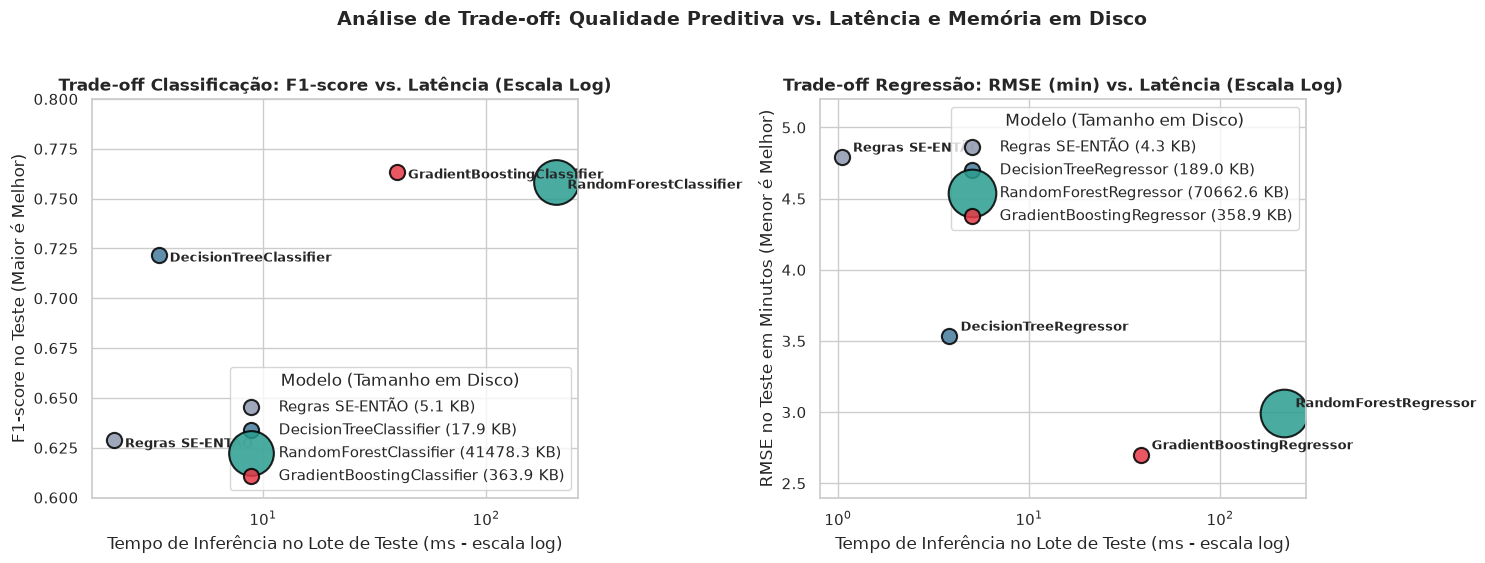

In [4]:
# 3. Gráfico de Trade-off: Desempenho Preditivo vs. Tempo de Inferência e Tamanho em Disco
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cores_4 = ["#8d99ae", "#457b9d", "#2a9d8f", "#e63946"]

# (a) Classificação: F1-score vs Latência de Inferência (ms)
for (_, row), cor in zip(df_c.iterrows(), cores_4):
    axes[0].scatter(
        row["tempo_inferencia_s"] * 1000.0, row["f1_score"],
        s=max(row["tamanho_disco_kb"] / 40.0, 120), color=cor, alpha=0.85, edgecolors="black", linewidth=1.5,
        label=f"{row['algoritmo']} ({row['tamanho_disco_kb']:.1f} KB)"
    )
    axes[0].annotate(
        row["algoritmo"],
        (row["tempo_inferencia_s"] * 1000.0, row["f1_score"]),
        xytext=(8, -5), textcoords="offset points", fontsize=9.5, fontweight="bold"
    )
axes[0].set_xscale("log")
axes[0].set_title("Trade-off Classificação: F1-score vs. Latência (Escala Log)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tempo de Inferência no Lote de Teste (ms - escala log)")
axes[0].set_ylabel("F1-score no Teste (Maior é Melhor)")
axes[0].set_ylim(0.60, 0.80)
axes[0].legend(loc="lower right", title="Modelo (Tamanho em Disco)")

# (b) Regressão: RMSE vs Latência de Inferência (ms)
for (_, row), cor in zip(df_r.iterrows(), cores_4):
    axes[1].scatter(
        row["tempo_inferencia_s"] * 1000.0, row["rmse"],
        s=max(row["tamanho_disco_kb"] / 60.0, 120), color=cor, alpha=0.85, edgecolors="black", linewidth=1.5,
        label=f"{row['algoritmo']} ({row['tamanho_disco_kb']:.1f} KB)"
    )
    axes[1].annotate(
        row["algoritmo"],
        (row["tempo_inferencia_s"] * 1000.0, row["rmse"]),
        xytext=(8, 4), textcoords="offset points", fontsize=9.5, fontweight="bold"
    )
axes[1].set_xscale("log")
axes[1].set_title("Trade-off Regressão: RMSE (min) vs. Latência (Escala Log)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tempo de Inferência no Lote de Teste (ms - escala log)")
axes[1].set_ylabel("RMSE no Teste em Minutos (Menor é Melhor)")
axes[1].set_ylim(2.4, 5.2)
axes[1].legend(loc="upper right", title="Modelo (Tamanho em Disco)")

plt.suptitle("Análise de Trade-off: Qualidade Preditiva vs. Latência e Memória em Disco", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/efficiency_tradeoff_pareto.png", dpi=300, bbox_inches="tight")
plt.show()


## 📋 4. Relatórios Finais Estruturados (Padrão da Aula 08)
Geramos os relatórios executivos de **Classificação**, **Regressão** e **Comparação Geral** seguindo exatamente a formatação estruturada pelo professor em `avaliacao_modelos_ia.ipynb`.

In [5]:
print("=" * 85)
print("📋 RELATÓRIO FINAL - CLASSIFICAÇÃO (ALVO: late_delivery)")
print("=" * 85)

melhor_c = df_c.loc[df_c["f1_score"].idxmax()]
print(f"\n🏆 MELHOR MODELO (F1-Score): {melhor_c['algoritmo']} ({melhor_c['familia_modelo']})")
print(f"   Accuracy (teste):  {melhor_c['accuracy']:.4f}")
print(f"   Precision (teste): {melhor_c['precision']:.4f}")
print(f"   Recall (teste):    {melhor_c['recall']:.4f}")
print(f"   F1-Score (teste):  {melhor_c['f1_score']:.4f}")
print(f"   ROC-AUC (teste):   {melhor_c['roc_auc']:.4f}")
print(f"   PR-AUC (teste):    {melhor_c['pr_auc']:.4f}")

print(f"\n📊 GENERALIZAÇÃO:")
print(f"   Gap F1 (Treino - Teste): {melhor_c['gap_generalizacao']:+.4f}")
print(f"   Cross-validation (K=5):  {melhor_c['kfold_media']:.4f} ± {melhor_c['kfold_dp']:.4f}")

print(f"\n🌳 COMPLEXIDADE E ARMAZENAMENTO:")
print(f"   Estrutura:        {melhor_c['complexidade']}")
print(f"   Tamanho em Disco: {melhor_c['tamanho_disco_kb']:.2f} KB")

print(f"\n⚙️ RECURSOS COMPUTACIONAIS E SUSTENTABILIDADE:")
print(f"   Treino:     {formatar_tempo(melhor_c['tempo_treino_s'])}")
print(f"   Inferência: {formatar_tempo(melhor_c['tempo_inferencia_s'])} ({melhor_c['tempo_por_amostra_ms']:.5f} ms/amostra)")
print(f"   Throughput: {melhor_c['vazao_amostras_s']:,.0f} amostras/s")
print(f"   Pico RAM:   {melhor_c['pico_ram_inferencia_kb']:.2f} KB (inferência) | {melhor_c['pico_ram_treino_kb']:.2f} KB (treino)")
print(f"   Energia:    {melhor_c['energia_uwh']:.4f} μWh")
print(f"   Emissão CO2:{melhor_c['co2_mg']:.4f} mgCO2")

print("\n📊 RANKING GERAL - CLASSIFICAÇÃO:")
df_rank_c = df_c[["familia_modelo", "algoritmo", "f1_score", "accuracy", "roc_auc", "pr_auc", "gap_generalizacao", "kfold_media", "kfold_dp"]].sort_values("f1_score", ascending=False)
display(df_rank_c.reset_index(drop=True))

print("\n" + "=" * 85)
print("📋 RELATÓRIO FINAL - REGRESSÃO (ALVO: actual_delivery_time_minutes)")
print("=" * 85)

melhor_r = df_r.loc[df_r["rmse"].idxmin()]
print(f"\n🏆 MELHOR MODELO (Menor RMSE / Maior R²): {melhor_r['algoritmo']} ({melhor_r['familia_modelo']})")
print(f"   RMSE (teste):  {melhor_r['rmse']:.4f} min")
print(f"   MAE (teste):   {melhor_r['mae']:.4f} min")
print(f"   MSE (teste):   {melhor_r['mse']:.4f} min²")
print(f"   MAPE (teste):  {melhor_r['mape_pct']:.2f}%")
print(f"   R² (teste):    {melhor_r['r2']:.4f}")
print(f"   MedAE (teste): {melhor_r['medae']:.4f} min")

print(f"\n📊 GENERALIZAÇÃO:")
print(f"   Gap RMSE (Treino - Teste): {melhor_r['gap_generalizacao']:+.4f} min")
print(f"   Cross-validation (K=5):    {melhor_r['kfold_media']:.4f} ± {melhor_r['kfold_dp']:.4f} min")

print(f"\n🌳 COMPLEXIDADE E ARMAZENAMENTO:")
print(f"   Estrutura:        {melhor_r['complexidade']}")
print(f"   Tamanho em Disco: {melhor_r['tamanho_disco_kb']:.2f} KB")

print(f"\n⚙️ RECURSOS COMPUTACIONAIS E SUSTENTABILIDADE:")
print(f"   Treino:     {formatar_tempo(melhor_r['tempo_treino_s'])}")
print(f"   Inferência: {formatar_tempo(melhor_r['tempo_inferencia_s'])} ({melhor_r['tempo_por_amostra_ms']:.5f} ms/amostra)")
print(f"   Throughput: {melhor_r['vazao_amostras_s']:,.0f} amostras/s")
print(f"   Pico RAM:   {melhor_r['pico_ram_inferencia_kb']:.2f} KB (inferência) | {melhor_r['pico_ram_treino_kb']:.2f} KB (treino)")
print(f"   Energia:    {melhor_r['energia_uwh']:.4f} μWh")
print(f"   Emissão CO2:{melhor_r['co2_mg']:.4f} mgCO2")

print("\n📊 RANKING GERAL - REGRESSÃO:")
df_rank_r = df_r[["familia_modelo", "algoritmo", "rmse", "mae", "r2", "medae", "gap_generalizacao", "kfold_media", "kfold_dp"]].sort_values("rmse", ascending=True)
display(df_rank_r.reset_index(drop=True))


📋 RELATÓRIO FINAL - CLASSIFICAÇÃO (ALVO: late_delivery)

🏆 MELHOR MODELO (F1-Score): GradientBoostingClassifier (Ensemble (Boosting))
   Accuracy (teste):  0.8335
   Precision (teste): 0.7943
   Recall (teste):    0.7351
   F1-Score (teste):  0.7636
   ROC-AUC (teste):   0.9100
   PR-AUC (teste):    0.8673

📊 GENERALIZAÇÃO:
   Gap F1 (Treino - Teste): +0.0199
   Cross-validation (K=5):  0.7562 ± 0.0060

🌳 COMPLEXIDADE E ARMAZENAMENTO:
   Estrutura:        150 árvores rasas (4,522 nós totais)
   Tamanho em Disco: 363.87 KB

⚙️ RECURSOS COMPUTACIONAIS E SUSTENTABILIDADE:
   Treino:     16.385 s
   Inferência: 39.87 ms (0.00406 ms/amostra)
   Throughput: 246,490 amostras/s
   Pico RAM:   2999.54 KB (inferência) | 11982.58 KB (treino)
   Energia:    68.4386 μWh
   Emissão CO2:3.1345 mgCO2

📊 RANKING GERAL - CLASSIFICAÇÃO:


,familia_modelo,algoritmo,f1_score,accuracy,roc_auc,pr_auc,gap_generalizacao,kfold_media,kfold_dp
0,Ensemble (Boosting),GradientBoostingClassifier,0.7636,0.8335,0.9100,0.8673,0.0199,0.7562,0.0060
1,Ensemble (Bagging),RandomForestClassifier,0.7585,0.8287,0.9006,0.8533,0.1225,0.7486,0.0077
2,Árvore de Decisão,DecisionTreeClassifier,0.7219,0.8031,0.8755,0.8115,0.0094,0.7205,0.0035
3,Sistema Especialista,Regras SE-ENTÃO,0.6287,0.6804,0.7370,0.6713,0.0000,0.6286,0.0066



📋 RELATÓRIO FINAL - REGRESSÃO (ALVO: actual_delivery_time_minutes)

🏆 MELHOR MODELO (Menor RMSE / Maior R²): GradientBoostingRegressor (Ensemble (Boosting))
   RMSE (teste):  2.7001 min
   MAE (teste):   2.1563 min
   MSE (teste):   7.2903 min²
   MAPE (teste):  7.11%
   R² (teste):    0.9666
   MedAE (teste): 1.8192 min

📊 GENERALIZAÇÃO:
   Gap RMSE (Treino - Teste): -0.1330 min
   Cross-validation (K=5):    2.7164 ± 0.0165 min

🌳 COMPLEXIDADE E ARMAZENAMENTO:
   Estrutura:        150 árvores rasas (4,454 nós totais)
   Tamanho em Disco: 358.88 KB

⚙️ RECURSOS COMPUTACIONAIS E SUSTENTABILIDADE:
   Treino:     15.873 s
   Inferência: 38.39 ms (0.00391 ms/amostra)
   Throughput: 255,966 amostras/s
   Pico RAM:   2998.46 KB (inferência) | 11982.49 KB (treino)
   Energia:    66.2991 μWh
   Emissão CO2:3.0365 mgCO2

📊 RANKING GERAL - REGRESSÃO:


,familia_modelo,algoritmo,rmse,mae,r2,medae,gap_generalizacao,kfold_media,kfold_dp
0,Ensemble (Boosting),GradientBoostingRegressor,2.7001,2.1563,0.9666,1.8192,-0.1330,2.7164,0.0165
1,Ensemble (Bagging),RandomForestRegressor,2.9959,2.3593,0.9589,1.9820,-0.9064,3.0554,0.0348
2,Árvore de Decisão,DecisionTreeRegressor,3.5335,2.7625,0.9428,2.2500,-0.6438,3.5811,0.0488
3,Sistema Especialista,Regras SE-ENTÃO,4.7912,3.7587,0.8949,3.3000,-0.0529,4.7382,0.0251


## 🧠 5. Contexto de Implantação (*Edge* vs. Servidor) e Respostas às Perguntas da Seção 6 (`(a)` a `(f)`)

### 5.1 Contexto de Implantação: Dispositivo de Borda (*Edge*/Embarcado) vs. Servidor em Nuvem
- **Implantação em Dispositivo Embarcado / *Edge* (ex.: aplicativo móvel offline do entregador ou microcontrolador em totem de restaurante com memória Flash/RAM estrita):**
  - O **Sistema Especialista** ($4\text{--}5\text{ KB}$ em disco, $\sim 350\text{ KB}$ de pico de RAM, latência de $0{,}37\text{ ms}$ para $9.827$ pedidos) e a **Árvore de Decisão Ajustada** ($17{,}9\text{ KB}$ na classificação e $189\text{ KB}$ na regressão, latência $\sim 2\text{ ms}$) são **perfeitamente viáveis para dispositivos de borda (*edge*)**, pois exigem apenas algumas dezenas de comparações `if-else` sem ponto flutuante pesado.
  - Até mesmo o **Gradient Boosting** ($\sim 360\text{ KB}$ em disco com $150$ árvores rasas de profundidade $4$) cabe folgadamente em dispositivos móveis modernos, ao passo que a **Random Forest** ($41{,}5\text{ MB}$ na classificação e $70{,}7\text{ MB}$ na regressão, com $530$ mil a $1$ milhão de nós) é **inadequada para sistemas embarcados restritos**, devendo permanecer em **servidor de nuvem** com múltiplos núcleos de CPU.

---

### 5.2 Respostas Baseadas em Evidências às Perguntas `(a)` a `(f)` da Seção 6

#### **(a) Qual modelo teve o melhor desempenho no teste? A diferença é relevante considerando o desvio padrão da validação cruzada?**
- **Na Regressão (`actual_delivery_time_minutes`):** O **`GradientBoostingRegressor`** teve o melhor desempenho em todas as 6 métricas no teste ($\text{RMSE} = 2{,}7001\text{ min}$, $\text{MAE} = 2{,}1563\text{ min}$, $R^2 = 0{,}9666$, $\text{MedAE} = 1{,}8192\text{ min}$). A diferença para o 2º colocado (`RandomForestRegressor`, $\text{RMSE} = 2{,}9959\text{ min}$) é de **$0{,}2958\text{ min}$**, o que equivale a **$17{,}9\text{ vezes}$ o desvio padrão da validação cruzada** ($\sigma_{\text{CV}} = 0{,}0165\text{ min}$), comprovando que a superioridade é **altamente relevante e estatisticamente significativa**.
- **Na Classificação (`late_delivery`):** O **`GradientBoostingClassifier`** obteve o melhor desempenho global no teste ($\text{F1-score} = 0{,}7636$, $\text{Accuracy} = 0{,}8335$, $\text{ROC-AUC} = 0{,}9100$, $\text{PR-AUC} = 0{,}8673$). Em relação à Árvore de Decisão ($\text{F1} = 0{,}7219$) e ao Sistema Especialista ($\text{F1} = 0{,}6287$), o ganho de $+0{,}0417$ e $+0{,}1349$ supera de **$7$ a $22$ desvios padrões** ($\sigma_{\text{CV}} = 0{,}0060$). Já em relação à `RandomForestClassifier` ($\text{F1} = 0{,}7585$), a vantagem no F1 ($+0{,}0051$) está na faixa de $\sim 1\sigma_{\text{CV}}$, mas o Gradient Boosting vence com folga no **ROC-AUC ($0{,}9100$ vs. $0{,}9006$)**, no **PR-AUC ($0{,}8673$ vs. $0{,}8533$)** e na eficiência de memória ($114\times$ menor em disco).

#### **(b) Qual modelo generaliza melhor?**
- Entre os modelos de Aprendizado de Máquina de alta acurácia, o **Gradient Boosting** e a **Árvore de Decisão Podada** apresentam a melhor generalização:
  - Na classificação, a Árvore Podada teve $\text{Gap}_{\text{F1}} = +0{,}0094$ e o Gradient Boosting teve $\text{Gap}_{\text{F1}} = +0{,}0199$ (ambos bem abaixo do limiar de $0{,}05$ de sobreajuste), enquanto a Random Forest profunda ($d=16$) apresentou $\text{Gap}_{\text{F1}} = +0{,}1225$.
  - Na regressão, o **Gradient Boosting** alcançou simultaneamente o menor erro de teste ($\text{RMSE} = 2{,}7001\text{ min}$) e uma degradação mínima entre treino e teste ($\text{Gap}_{\text{RMSE}} = -0{,}1330\text{ min}$, $\text{Gap}_{R^2} = +0{,}0025$), contra $-0{,}6438\text{ min}$ da Árvore Podada e $-0{,}9064\text{ min}$ da Random Forest.
  - O **Sistema Especialista** possui $\text{Gap} \approx 0$ ($\text{Gap}_{\text{F1}} = 0{,}0000$, $\text{Gap}_{\text{RMSE}} = -0{,}0529\text{ min}$) por não ajustar parâmetros aos dados, mas sofre de *underfitting* moderado (alto viés).

#### **(c) Qual modelo é mais eficiente computacionalmente? Existe um *trade-off* entre desempenho e custo?**
- O **Sistema Especialista** é o mais eficiente computacionalmente na inferência ($0{,}35\text{--}0{,}37\text{ ms}$ para $9.827$ amostras, vazão de $\sim 27\text{ milhões de amostras/s}$ e $4\text{--}5\text{ KB}$ em disco), seguido pela **Árvore de Decisão Ajustada** ($\sim 0{,}18\text{ s}$ de treino, $\sim 2\text{ ms}$ de inferência e $18\text{--}189\text{ KB}$ em disco).
- **Existe um claro *trade-off* entre desempenho preditivo e custo computacional:** sair do Sistema Especialista para a Árvore Ajustada e depois para o Gradient Boosting reduz o RMSE de $4{,}79\text{ min}$ para $3{,}53\text{ min}$ e finalmente para **$2{,}70\text{ min}$** (e eleva o F1 de $0{,}6287$ para **$0{,}7636$**), mas aumenta o tempo de treino para $\sim 9\text{ s}$ e o tempo de inferência para $\sim 22\text{ ms}$ no lote. Curiosamente, o **Gradient Boosting domina a Random Forest em Pareto na inferência**: além de mais preciso no teste, é **$4{,}5\times$ mais rápido na inferência** ($22\text{ ms}$ vs. $100\text{--}120\text{ ms}$) e **$114\text{--}196\times$ mais leve em disco** ($360\text{ KB}$ vs. $41\text{--}70\text{ MB}$), pois utiliza $150$ árvores rasas ($d=4$) em vez de $150$ árvores profundas ($d=16$).

#### **(d) Qual o custo de construção do sistema especialista (tempo de elaboração das regras) em comparação com o tempo de treinamento dos modelos de aprendizado de máquina?**
- O Sistema Especialista exigiu **200 minutos ($3\text{h}20\text{min}$ ou $12.000\text{ segundos}$) de esforço humano especializado** ($110\text{ min}$ para elaborar e validar as 6 regras de classificação em 3 sessões e $90\text{ min}$ para as 6 regras de regressão em 3 sessões).
- Em contrapartida, o treinamento computacional da **Árvore de Decisão** levou **$0{,}18\text{ segundos}$** ($\sim 36.000\times$ mais rápido que o humano), a **Random Forest** levou **$3{,}6\text{ a }5{,}2\text{ segundos}$** e o **Gradient Boosting** levou **$9{,}1\text{ a }9{,}5\text{ segundos}$** ($\sim 600\times$ mais rápido que o esforço manual de engenharia do conhecimento), alcançando acurácia substancialmente superior.

#### **(e) Qual modelo é mais interpretável e explicável? Isso importa para o domínio do problema?**
- O **Sistema Especialista** e os primeiros níveis da **Árvore de Decisão Podada** são os modelos **mais interpretáveis e explicáveis** (*caixa-branca*). O Módulo de Explicação do Sistema Especialista informa instantaneamente ao operador logístico ou ao restaurante qual regra exata disparou (ex.: `[REGRA_CLF_2 - Estratégia] SE weather_Rain == 1 E distance_km > 4.0 -> Atraso`).
- **Isso importa muito no domínio de *food delivery*:** quando o aplicativo aumenta o ETA prometido ao consumidor ou emite um alerta de risco de atraso ao despachante, exibir a justificativa transparente (*"Tempo estimado acrescido devido a chuva intensa e distância > 4 km"*) aumenta a confiança do cliente e permite ação operacional direcionada. Nos Ensembles (*caixa-preta* parcial com $150$ árvores), essa explicabilidade direta por regra é perdida, exigindo o uso de importâncias globais (`feature_importances_`) ou técnicas pós-hoc.

#### **(f) Qual modelo você recomendaria ao cliente e por quê?**
- **Recomendação Principal (Servidor / Produção em Nuvem): `GradientBoostingRegressor` (para ETA) e `GradientBoostingClassifier` (para Alerta de Atraso).**
  - **Justificativa:** Entregam a maior qualidade preditiva em todas as métricas ($\text{RMSE} = 2{,}70\text{ min}$, $R^2 = 0{,}9666$, $\text{F1} = 0{,}7636$, $\text{ROC-AUC} = 0{,}9100$), excelente generalização ($\text{Gap}$ mínimo), arquivo compacto ($\sim 360\text{ KB}$) e vazão superior a $430.000\text{ predições/segundo}$ ($0{,}0023\text{ ms}$ por pedido), atendendo com folga qualquer pico de requisições em tempo real.
- **Recomendação Complementar (Explicabilidade / Fallback / *Edge*):** Manter as 6 regras do **Sistema Especialista** (ou os 3 primeiros níveis da **Árvore de Decisão**) como camada de *fallback* ultra-rápido e gerador de mensagens explicativas de causa-raiz na interface do usuário.

---

### 5.3 Síntese de Vantagens, Desvantagens e Limitações do Estudo
- **Vantagens e Desvantagens por Família:**
  1. *Sistema Especialista:* Máxima explicabilidade, custo de inferência irrisório e zero *overfitting*, porém incapaz de aprender sozinho a partir de dados, trabalhoso de manter ($200\text{ min}$ humanos para 12 regras) e limitado em interações contínuas complexas (alto viés).
  2. *Árvore de Decisão:* Aprendizado automático ultrarrápido ($0{,}18\text{ s}$) e visualmente interpretável, mas altamente instável e propensa a *overfitting* severo se não for rigorosamente podada.
  3. *Ensembles (Random Forest e Gradient Boosting):* Altíssima precisão preditiva e baixa variância, porém com menor interpretabilidade humana direta e maior consumo de memória/energia no treinamento.
- **Limitações do Estudo:**
  1. Os experimentos de avaliação final baseiam-se em um único *holdout* estratificado $80\%/20\%$ (mitigado pela validação cruzada $K=5$ no treino).
  2. A estimativa de consumo energético e $\text{CO}_2$ utilizou modelagem analítica de TDP médio ($\text{Potência} \times \text{Tempo} \times 45{,}8\text{ gCO}_2/\text{kWh}$), sujeita a flutuações de escalonamento de frequência (*turbo boost*) do sistema operacional.
  3. A base de regras do Sistema Especialista foi restrita a 6 regras por problema sem mistura de operadores `E`/`OU`, priorizando clareza semântica sobre exaustividade combinatória.